# 3.1.- Validación de Modelos

In [1]:
# NumPy y Pandas
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 1. Análisis exploratorio de datos (EDA)

Antes de entrenar un modelo de regresión, debemos entender la naturaleza de nuestros datos.  
Algunas de las preguntas iniciales son:

- ¿Qué variables tenemos disponibles?  
- ¿Existen valores faltantes o anomalías?  
- ¿Cuál es la distribución de cada variable?  
- ¿Cómo se relacionan las variables predictoras con la variable objetivo?  

En este caso, nuestro dataset contiene variables relacionadas con componentes de mezclas de cemento, y la variable objetivo es la **resistencia del cemento**.

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Dimensiones del dataset: (1030, 9)


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225



Valores nulos por columna:
Cement                0
Blast_Furnace_Slag    0
Fly_Ash               0
Water                 0
Superplasticizer      0
Coarse_Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64


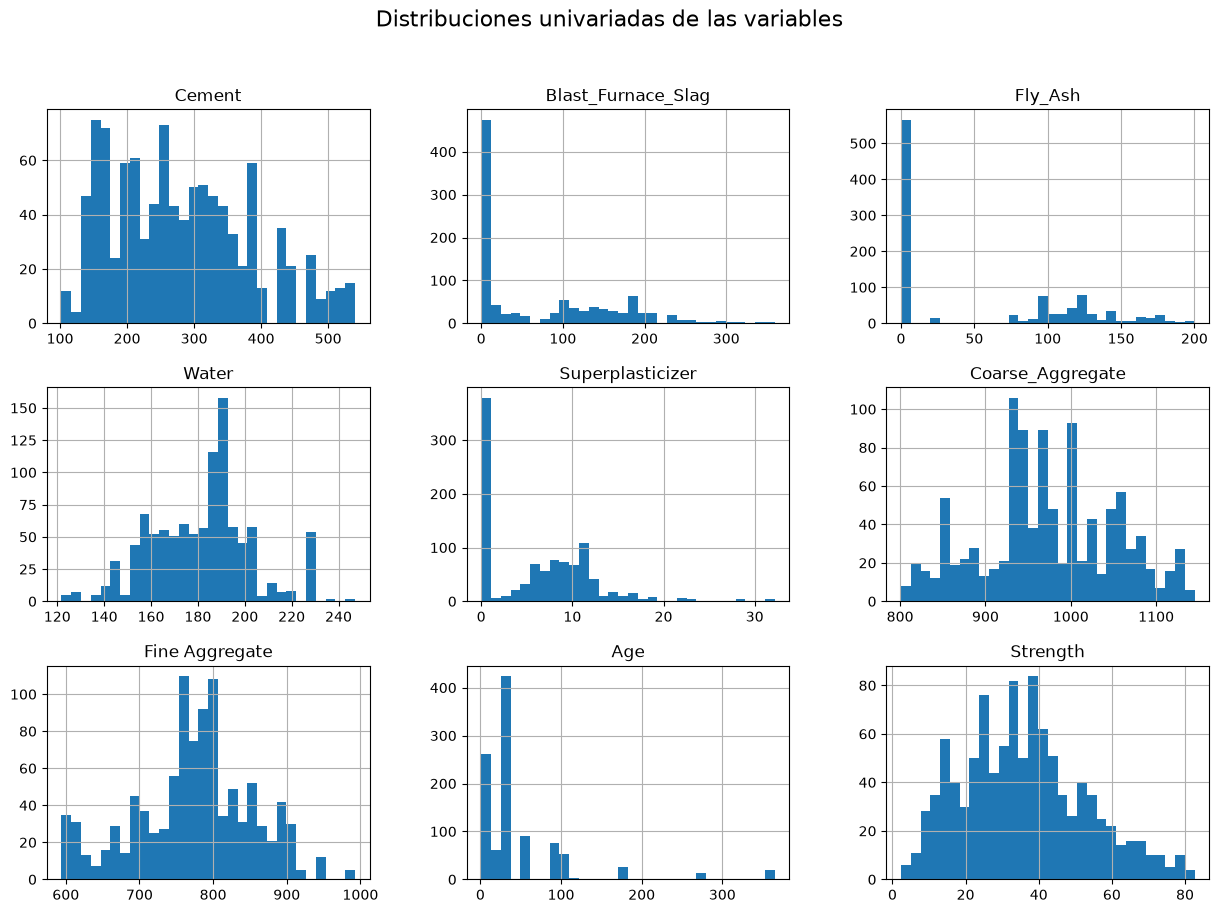

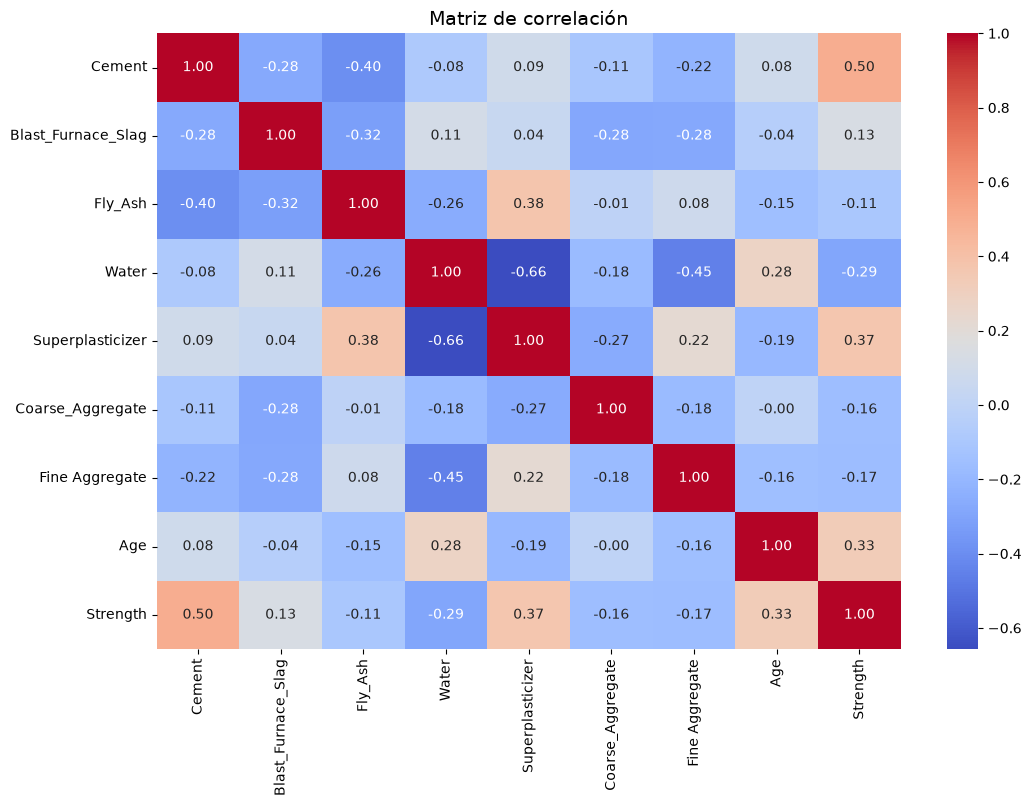

In [2]:
# Cargar datos
df = pd.read_csv("https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/concrete_data.csv")

# Primer vistazo
display(df.head())
print("\nDimensiones del dataset:", df.shape)

# Resumen estadístico
display(df.describe())

# Revisar valores nulos
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Histogramas univariados
df.hist(bins=30, figsize=(15, 10))
plt.suptitle("Distribuciones univariadas de las variables", fontsize=16)
plt.show()

# Matriz de correlación
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación", fontsize=14)
plt.show()

## 2. División de los datos en entrenamiento y test

Para evaluar correctamente un modelo, necesitamos separar el dataset en dos subconjuntos:

- **Conjunto de entrenamiento (train):** utilizado para ajustar los parámetros del modelo.
- **Conjunto de prueba (test):** utilizado únicamente para evaluar el rendimiento del modelo en datos no vistos.

Esto evita el problema de sobreajuste y nos da una estimación más realista del desempeño del modelo en producción.

Usaremos un `80%` de los datos para train y `20%` para test.

In [3]:
# Definir variables predictoras (X) y variable objetivo (y)
X = df.drop("Strength", axis=1)
y = df["Strength"]

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=33
)

print("Tamaño del conjunto de entrenamiento:", X_train.shape)
print("Tamaño del conjunto de prueba:", X_test.shape)

Tamaño del conjunto de entrenamiento: (824, 8)
Tamaño del conjunto de prueba: (206, 8)


## 3. Reescalado de los datos

En regresión lineal, es importante reescalar los datos porque:

- Las variables tienen magnitudes muy diferentes (ej. `Superplasticizer` va de 0–20, mientras que `Coarse_Aggregate` está en cientos).
- Un modelo sin escalar puede dar más peso a variables con valores más grandes solo por su escala.
- El reescalado mejora la estabilidad numérica y la convergencia de métodos como el descenso de gradiente.

Usaremos **StandardScaler**, que transforma cada variable para que tenga:

- Media = 0
- Desviación estándar = 1

In [4]:
# Inicializar el escalador
scaler = StandardScaler()

# Ajustar y transformar en train
X_train_scaled = scaler.fit_transform(X_train)

# Transformar también test (usando los parámetros de train)
X_test_scaled = scaler.transform(X_test)

# Verificación
print("Media (train):", X_train_scaled.mean(axis=0)[:3])   # primeras 3 features
print("Std (train):", X_train_scaled.std(axis=0)[:3])

Media (train): [ 2.82406245e-16 -1.03477097e-16 -1.07788643e-16]
Std (train): [1. 1. 1.]


## 4. Definición de nuestro predictor

Vamos a utilizar **Regresión Lineal** como modelo base.  

En este contexto:
- El predictor aprende los coeficientes (pesos) que multiplican cada variable predictora.
- Estos coeficientes nos indicarán la **importancia** de cada variable en la predicción de la resistencia del concreto.
- El modelo también ajusta un intercepto (β₀).

Usaremos la implementación de `LinearRegression` de `scikit-learn`.

In [5]:
# Definición del modelo
modelo = LinearRegression()

# Ajustar (fit) con los datos escalados
modelo.fit(X_train_scaled, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


## 5. Importancia de las variables en la predicción

Una vez entrenado el modelo, podemos observar los **coeficientes (βⱼ)** que acompañan a cada variable:

- Un coeficiente positivo indica que, al aumentar esa variable, la resistencia del concreto tiende a **aumentar** (manteniendo el resto fijo).  
- Un coeficiente negativo indica que al aumentar la variable, la resistencia tiende a **disminuir**.  
- La magnitud del coeficiente refleja la **importancia relativa** de la variable en la predicción.

Nota: los coeficientes son comparables porque hemos **reescalado los datos** previamente.

Cement                13.231733
Blast_Furnace_Slag     9.514806
Age                    7.284160
Fly_Ash                6.318811
Fine Aggregate         2.150318
Coarse_Aggregate       1.997878
Superplasticizer       1.474570
Water                 -2.565900
dtype: float64


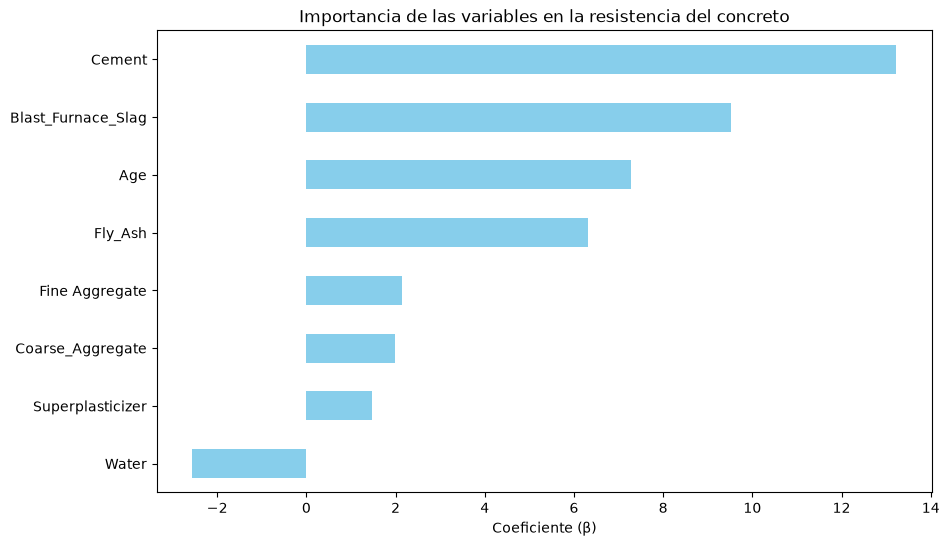

In [6]:
# Extraer coeficientes
coeficientes = pd.Series(modelo.coef_, index=X.columns)

# Mostrar ordenados
print(coeficientes.sort_values(ascending=False))

# Visualización
plt.figure(figsize=(10,6))
coeficientes.sort_values().plot(kind="barh", color="skyblue")
plt.title("Importancia de las variables en la resistencia del concreto")
plt.xlabel("Coeficiente (β)")
plt.show()

## 6. Puntuación de referencia (baseline score)

Antes de evaluar el modelo, necesitamos un **punto de comparación**.

El modelo más simple posible sería siempre predecir el mismo valor para todos los ejemplos.  
Por ejemplo:
- Usar la **media del conjunto de entrenamiento** como predicción constante.  

Este baseline nos permite responder:
¿Nuestro modelo realmente mejora respecto a una estrategia trivial?

In [7]:
# Predicción constante con la media de y_train
y_pred_baseline = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)

# Calcular métricas
mse_baseline = mean_squared_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Baseline - siempre predecir la media")
print("RMSE:", rmse_baseline)
print("R²:", r2_baseline)

Baseline - siempre predecir la media
RMSE: 17.22695832371192
R²: -0.00020774434137060815


## 7. Validación cruzada (Cross-validation score)

Al trabajar con un **dataset pequeño (~1000 muestras)**, el error obtenido en un único train/test split puede depender mucho de **cómo se dividieron los datos**.  

Para obtener una evaluación más robusta, utilizamos **validación cruzada (cross-validation)**:
- Dividimos el conjunto de entrenamiento en *K* particiones (folds).
- Entrenamos el modelo *K* veces, cada vez con un fold diferente como validación.
- Calculamos la métrica en cada fold y hacemos la media.

Esto nos da una estimación más estable del rendimiento del modelo.

In [8]:
# Validación cruzada con 5 folds usando R²
scores = cross_val_score(
    modelo, X_train_scaled, y_train, cv=5, scoring="r2"
)

print("Scores en cada fold:", scores)
print("Media R²:", scores.mean())
print("Desviación estándar R²:", scores.std())

Scores en cada fold: [0.60283139 0.67176652 0.55627999 0.51087878 0.64481841]
Media R²: 0.5973150168878851
Desviación estándar R²: 0.058284006381648296


## 8. Entrenamiento completo (Full Fit)

Después de haber validado el modelo con *cross-validation*, entrenamos de nuevo el modelo usando **todo el conjunto de entrenamiento**.  

Luego evaluamos su rendimiento en el conjunto de **prueba (test)**, que se mantuvo aparte durante todo el proceso.  
De esta manera obtenemos una estimación **realista** del desempeño en datos nuevos.

In [9]:
# Reentrenar el modelo en todo el conjunto de entrenamiento
modelo.fit(X_train_scaled, y_train)

# Predicciones en el conjunto de test
y_pred_test = modelo.predict(X_test_scaled)

# Métricas de rendimiento en test
mse_test = mean_squared_error(y_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_pred_test)

print("Resultados en el conjunto de prueba (test):")
print("RMSE:", rmse_test)
print("R²:", r2_test)

Resultados en el conjunto de prueba (test):
RMSE: 10.484062239201025
R²: 0.6295477919215545


## 9. Resultados y Conclusiones

- **Baseline (modelo trivial, predice la media):**
  - RMSE relativamente alto.
  - R² cercano a 0 → apenas explica la variabilidad de los datos.

- **Validación cruzada (5 folds):**
  - R² medio positivo → el modelo logra explicar una parte significativa de la variabilidad.
  - La desviación estándar muestra la estabilidad del modelo: si es pequeña, el modelo es consistente.

- **Evaluación final en test:**
  - RMSE más bajo que el baseline → el modelo mejora respecto a la estrategia trivial.
  - R² claramente mayor que 0 → el modelo generaliza de manera aceptable en datos no vistos.

### Conclusión
La **regresión lineal** aplicada a este dataset es capaz de capturar parte de la relación entre los ingredientes del concreto y su resistencia final.  
Aunque no es un modelo perfecto (todavía quedan errores significativos), sí mejora de manera consistente frente al baseline y constituye un buen punto de partida.